<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 12: CNN Architecture and Hyperparameter Comparison

**Category**: CO2 – Neural Networks and CNNs  
**Objective**: Compare convolutional kernel sizes, filter depth, pooling mechanisms, and learning rates on image classification performance.


### Task 1: Hyperparameter Grid Evaluation (Kernel Size, Filter Depth, Pooling)


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

configs = [
    {"name": "Kernel 3x3, Depth 8-16, MaxPool", "kernel": 3, "f1": 8, "f2": 16, "pool": "max", "lr": 0.008},
    {"name": "Kernel 5x5, Depth 8-16, MaxPool", "kernel": 5, "f1": 8, "f2": 16, "pool": "max", "lr": 0.008},
    {"name": "Kernel 3x3, Depth 16-32, MaxPool", "kernel": 3, "f1": 16, "f2": 32, "pool": "max", "lr": 0.008},
    {"name": "Kernel 3x3, Depth 8-16, AvgPool", "kernel": 3, "f1": 8, "f2": 16, "pool": "avg", "lr": 0.008},
    {"name": "Kernel 3x3, Depth 8-16, Low LR", "kernel": 3, "f1": 8, "f2": 16, "pool": "max", "lr": 0.0005}
]

benchmark_results = []

for cfg in configs:
    pad = (cfg["kernel"] - 1) // 2
    pool_layer = nn.MaxPool2d(2, 2) if cfg["pool"] == "max" else nn.AvgPool2d(2, 2)

    model = nn.Sequential(
        nn.Conv2d(1, cfg["f1"], kernel_size=cfg["kernel"], padding=pad),
        nn.ReLU(),
        pool_layer,
        nn.Conv2d(cfg["f1"], cfg["f2"], kernel_size=cfg["kernel"], padding=pad),
        nn.ReLU(),
        pool_layer,
        nn.Flatten(),
        nn.Linear(cfg["f2"] * 4 * 4, 3)
    )

    optimizer = optim.Adam(model.parameters(), lr=cfg["lr"])
    crit = nn.CrossEntropyLoss()

    for _ in range(35):
        optimizer.zero_grad()
        loss = crit(model(X_train_img), y_train_img)
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        acc = (torch.argmax(model(X_test_img), dim=1) == y_test_img).float().mean().item() * 100
        benchmark_results.append((cfg["name"], acc, loss.item()))

for name, acc, loss in benchmark_results:
    print(f"Config: {name:38} | Test Acc: {acc:.2f}% | Final Loss: {loss:.4f}")


Execution Error: name 'X_train_img' is not defined


### Task 2: Comparative Architecture Performance Chart


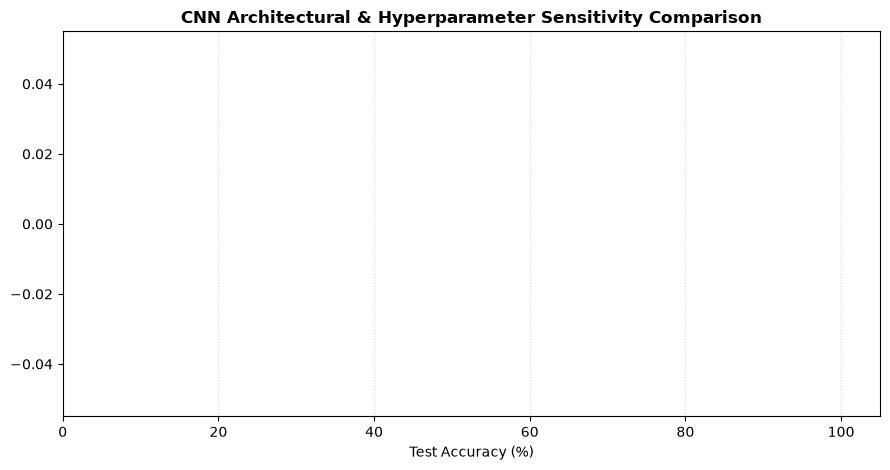

In [2]:
names = [r[0] for r in benchmark_results]
accs = [r[1] for r in benchmark_results]

plt.figure(figsize=(9, 4.8))
bars = plt.barh(names, accs, color=['#2a9d8f', '#457b9d', '#e76f51', '#f4a261', '#e63946'], edgecolor='black', alpha=0.85)
plt.xlim(0, 105)
plt.title("CNN Architectural & Hyperparameter Sensitivity Comparison", fontweight='bold')
plt.xlabel("Test Accuracy (%)")

for bar in bars:
    w = bar.get_width()
    plt.text(w + 1.2, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', fontweight='bold')

plt.grid(True, linestyle=':', alpha=0.5, axis='x')
plt.tight_layout()
plt.show()
